In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("hwk3-task2-spills-STACK.ipynb")

/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/nbformat/validator.py:434: DuplicateCellId: Non-unique cell id '4d52d6d9-e745-43b4-9320-6f54aa03165d' detected. Corrected to '9a476dff'.
  _validate(nbdict, ref, version, version_minor, relax_add_props)
/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/nbformat/validator.py:434: DuplicateCellId: Non-unique cell id 'cb27288e-e39c-424a-a6d9-91246bc5ccb8' detected. Corrected to '8a126ae5'.
  _validate(nbdict, ref, version, version_minor, relax_add_props)
/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/nbformat/validator.py:434: DuplicateCellId: Non-unique cell id 'b134f8b7-4527-44b2-95f8-2e55880dd4f0' detected. Corrected to '8bbf541e'.
  _validate(nbdict, ref, version, version_minor, relax_add_props)


# Task 2: Visualizing oil spills in NY State

## Instructions

- First, update the following cell to have a link to *your* Homework 3 GitHub repository:

**UPDATE THIS LINK**
https://github.com/farahjstack/eds220-hwk3.git


- Review the [complete rubric for this task](https://docs.google.com/document/d/1Ce4EO3MEHW5uLks4x8BECWlkim2bcmxB4f8Qo4z26z8/edit?usp=sharing) before starting.

- **Meaningful commits should be made every time you finish a major step.** We'll check your repository and view the commit history.

- Comment mindfully in a way that enriches your code. Comments should follow best practices.

- **Do not update the top cell with the `otter` import**, this is used internally for grading.


## About the data
In this task you will use two datasets:

### First dataset: oil spills data

The first dataset contains information about [spilling incidents in the state of New York](https://data.ny.gov/Energy-Environment/Spill-Incidents/u44d-k5fk). Make sure you study the data portal and understand what each row represents before starting to code. 
You will find extra information and metadata for this dataset in the `NYSDEC_SpillIncidents_Overview.pdf` and `NYSDEC_SpillIncidents_DataDictionary.pdf` documents available at the portal.

### Second dataset: TIGER shapefile

The second dataset is the [2026 Counties (and equivalent) TIGER shapefile](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html) (file `tl_2026_us_county.zip`) from the Census Bureau. You can check the [metadata for all the TIGER shapefiles here](https://www.census.gov/programs-surveys/geography/technical-documentation/complete-technical-documentation/tiger-geo-line.html). 

### COMPLETE WORKFLOW
You will use the next code cell to complete the last exercise in the task. Leave it blank for now.

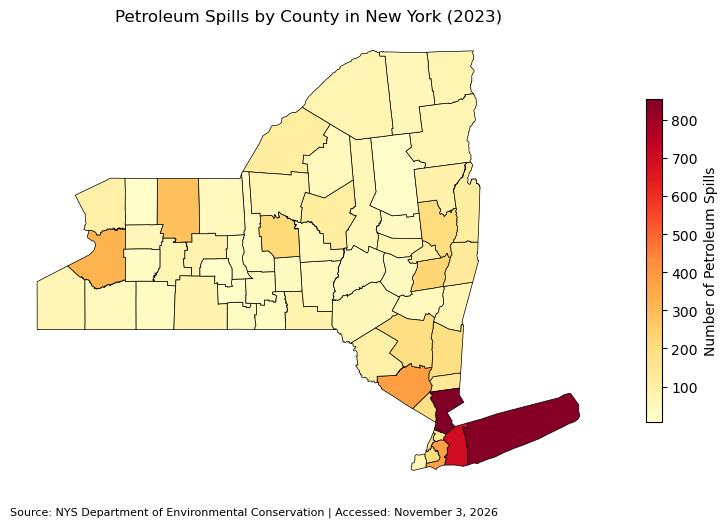

In [2]:
# FINAL CODE

# Import libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

# Read in NY spills data
spills_fp = os.path.join("data", "Spill_Incidents_20261103.csv")
spills = pd.read_csv(spills_fp)

# Read in US counties data
counties_fp = os.path.join("data", "tl_2026_us_county", "tl_2026_us_county.shp")
counties = gpd.read_file(counties_fp)

# Make all columns lower case
spills.columns = spills.columns.str.lower()
counties.columns = counties.columns.str.lower()

# Convert spill date into a datetime format
spills['spill date'] = pd.to_datetime(spills['spill date'])

# Filter petroleum spills for the entire year of 2023
petr_full_2023 = spills.loc[
    (spills['material family'] == 'Petroleum') &
    (spills['spill date'] >= '2023-01-01') &
    (spills['spill date'] < '2024-01-01')
]

# Group petroleum spills by county and count unique spill numbers
spills_per_county = petr_full_2023.groupby('county')['spill number'].nunique()

# Reset the index and rename the count column
spills_per_county = spills_per_county.reset_index(name='n_spills')

# Select counties only in NY state (FIPS code 36)
ny_counties = counties.loc[counties['statefp'] == "36"]

# Find county names in spills_per_county that are not in ny_counties
diff_names_spills = np.setdiff1d(
    spills_per_county['county'].unique(),
    ny_counties['name'].unique()
).tolist()

# Find county names in ny_counties that are not in spills_per_county
diff_names_ny = np.setdiff1d(
    ny_counties['name'].unique(),
    spills_per_county['county'].unique()
).tolist()

# Select spill records for the two reservations
reservation_spills = spills_per_county.loc[
    spills_per_county['county'].isin([
        'Tuscarora Indian Reservation',
        'Onondaga Indian Reservation'
    ])
]

# Update St Lawrence to St. Lawrence
spills_per_county['county'] = spills_per_county['county'].replace(
    'St Lawrence', 'St. Lawrence'
)

# Verify the update was successful
assert 'St. Lawrence' in spills_per_county['county'].values
assert 'St Lawrence' not in spills_per_county['county'].values

# Merge spill counts with New York county geometries
ny_spills = pd.merge(
    spills_per_county,
    ny_counties,
    left_on='county',
    right_on='name',
    how='inner'
)

# Find records dropped during the inner join
dropped_records = spills_per_county.loc[
    ~spills_per_county['county'].isin(ny_spills['county'])
]

# Add reservation spills to corresponding counties
ny_spills.loc[ny_spills['county'] == 'Niagara', 'n_spills'] += 2
ny_spills.loc[ny_spills['county'] == 'Onondaga', 'n_spills'] += 1

# Convert to GeoDataFrame
ny_spills = gpd.GeoDataFrame(
    ny_spills,
    geometry='geometry',
    crs=ny_counties.crs
)

# Create choropleth map
fig, ax = plt.subplots(figsize=(10, 6))

ny_spills.plot(
    column='n_spills',
    cmap='YlOrRd',
    legend=True,
    edgecolor='black',
    linewidth=0.5,
    ax=ax,
    legend_kwds={
        'label': 'Number of Petroleum Spills',
        'shrink': 0.7
    }
)

# Update map
ax.set_title('Petroleum Spills by County in New York (2023)')
ax.set_axis_off()

# Add data source
ax.text(
    0, -0.05,
    'Source: NYS Department of Environmental Conservation | Accessed: November 3, 2026',
    transform=ax.transAxes,
    fontsize=8
)

# Display final map
plt.show()




## 1. File management
a. Any data you download should go in the `data/` folder of your `eds220-hwk3` repository. For example, after downloading both datasets, your repository should look like this:

```
eds220-hwk3/
├── data/
│   ├── q5d_df.csv
│   ├── Spill_Incidents_20261027.csv
│   └── tl_2026_us_county/
│       ├── tl_2026_us_county.cpg
│       ├── tl_2026_us_county.dbf
│       ├── tl_2026_us_county.prj
│       ├── tl_2026_us_county.shp
│       └── ... (other files from the shapefile)
├── tests/
├── .gitignore
├── LICENSE
├── README.md
└── hwk3-task2-spills.ipynb
```

The date in the name of the spills file may be different, depending on when you download it. `data/q5d_df.csv` is already in the repository and is used by the autograder tests, so do not delete or move it.

**IMPORTANT: Do not commit your data!**

The datasets we'll be working with are large and will most likely jam your commit history if git does not ignore them.

b. Add the relative path of each dataset you downloaded to your `.gitignore` file. For example, to ignore the folder containing the shapefile, add `data/tl_2026_us_county/` to the `.gitignore`.

c. Commit and push your changes to the `.gitignore`.

d. Run `git status` and verify that none of your data is being tracked by git.

## 2. Datasets description
- Read the metadata for both datasets and write a brief description about each one. Indicate the data sources and date of access.

Dataset 1: New York State Spill Incidents

The first dataset, Spill Incidents, is provided by the New York State Department of Environmental Conservation (NYSDEC), Division of Environmental Remediation. It contains statewide records of reported petroleum and other hazardous material spills that may contaminate New York's land or water resources. Under New York State laws and regulations, spills must be reported by responsible parties and, in certain circumstances, by individuals with knowledge of an incident. Each record includes information such as the spill date and time, geographic location, facility name, source and cause of the spill, and the type of material released. The dataset was originally published on October 19, 2015, and is updated daily to reflect ongoing spill reporting.

- Date accessed: November 3, 2026
- Last updated: November 3, 2026
- Geographic coverage: New York State
- Data source: New York State Department of Environmental Conservation, Division of Environmental Remediation

Dataset 2: 2026 TIGER/Line Shapefiles
The second dataset, 2026 TIGER/Line Shapefiles, is provided by the U.S. Census Bureau and contains geographic boundaries and spatial features for the United States, District of Columbia, Puerto Rico, and U.S. Island Areas. The shapefiles represent both legal and statistical geographic entities, including states, counties, census tracts, school districts, and other administrative boundaries. The dataset also includes geographic features such as roads, rivers, coastlines, and landmarks, represented as point, line, and polygon geometries. These data are derived from the Census Bureau's Master Address File/Topologically Integrated Geographic Encoding and Referencing (MAF/TIGER) System and can be used for mapping, spatial analysis, and examining geographic patterns.

- Date accessed: November 3, 2026
- Geographic coverage: United States, District of Columbia, Puerto Rico, and U.S. Island Areas
- Data source: U.S. Census Bureau, 2026 TIGER/Line Shapefiles



## 3. Import libraries

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

## 4. Import data 
In the next cell:

- Import the NY spills data as a variable named `spills`. 
- Import the US counties data as a variable named `counties`.

If you are using file paths to access the data, these should be constructed using the `os` package.

In [4]:
# NY spills data 
spills_fp = os.path.join("data", "Spill_Incidents_20261103.csv")
spills = pd.read_csv(spills_fp)

# US counties data 
counties_fp = os.path.join("data", "tl_2026_us_county", "tl_2026_us_county.shp")
counties = gpd.read_file(counties_fp)

<!-- BEGIN QUESTION -->

## 5. Prepare spills data

This section refers to the `spills` dataframe. 
Check the outputs carefully, they will give you information you will need to use in the next exercises.

### 5.A. Exploration

In the next cells:

a. Check the dataframe's head

b. Check the data types of the columns

c. Check the unique values in the `material_family` column

d. Check the unique values in the `county` column

e. Insert a markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells for preliminary data exploration.

By applying `head()`, I was able to preview the first five rows of the dataset and better understand how the information is organized across its columns. For example, the `Spill Number` column contains a six-digit identifier for each spill, `Program Facility Name` identifies the facility associated with the spill, and `Street 1` provides its street address. The dataset also includes geographic information, such as the county where each spill occurred, along with details about the spill date, when the report was received, whether the spill source was known or unknown, and whether it was associated with a commercial or industrial activity.

By applying `spills.info()`, I learned more about the dataset's overall structure. The output showed that the dataset is a pandas DataFrame containing 574,758 entries, along with the names of each column, the number of non-null values, and each column's data type. The non-null counts are particularly useful because they help identify columns with missing information (which there's alot of missing information!).

Finally, by examining specific columns and their unique values, I was able to better understand the types of information recorded in the dataset. For example, looking at the unique values in the `Material Family` column helped me identify the different categories of materials involved in reported spills. Similarly, examining the unique values in the `County` column showed me the different counties represented in the dataset.

In [5]:
#a. Check the dataframe's head

spills.head()

,Spill Number,Program Facility Name,Street 1,Street 2,Locality,County,ZIP Code,SWIS Code,DEC Region,Spill Date,Received Date,Contributing Factor,Waterbody,Source,Close Date,Material Name,Material Family,Quantity,Units,Recovered
0,107132,MH 864,RT 119/MILLWOOD RD,NaN,ELMSFORD,Westchester,NaN,6000,3,10/10/2001,10/10/2001,Unknown,NaN,Unknown,10/15/2001,unknown material,Other,10,Gallons,0
1,405586,BOWRY BAY,WATER POLL CONTROL,NaN,QUEENS,Queens,NaN,4101,2,08/21/2004,08/21/2004,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0,NaN,0
2,405586,BOWRY BAY,WATER POLL CONTROL,NaN,QUEENS,Queens,NaN,4101,2,08/21/2004,08/21/2004,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0,Pounds,0
3,204667,POLE 16091,GRACE AVE/BURKE AVE,NaN,BRONX,Bronx,NaN,301,2,08/02/2002,08/02/2002,Equipment Failure,NaN,Commercial/Industrial,10/28/2002,transformer oil,Petroleum,1,Gallons,0
4,210559,POLE ON,FERDALE LOMIS RD / RT 52,NaN,LIBERTY,Sullivan,NaN,5336,3,01/20/2003,01/20/2003,Traffic Accident,NaN,Commercial/Industrial,01/22/2003,transformer oil,Petroleum,6,Gallons,6


In [6]:
#b. Check the data types of the columns
spills.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 574758 entries, 0 to 574757
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype 
---  ------                 --------------   ----- 
 0   Spill Number           574758 non-null  int64 
 1   Program Facility Name  574752 non-null  object
 2   Street 1               574624 non-null  object
 3   Street 2               44737 non-null   object
 4   Locality               573607 non-null  object
 5   County                 574758 non-null  object
 6   ZIP Code               57918 non-null   object
 7   SWIS Code              574758 non-null  int64 
 8   DEC Region             574758 non-null  int64 
 9   Spill Date             574607 non-null  object
 10  Received Date          574255 non-null  object
 11  Contributing Factor    574758 non-null  object
 12  Waterbody              47992 non-null   object
 13  Source                 574758 non-null  object
 14  Close Date             562343 non-null  object
 15  

In [7]:
#c. Check the unique values in the `material_family` column
spills['Material Family'].unique()

array(['Other', 'Petroleum', 'Hazardous Material', 'Oxygenates'],
      dtype=object)

In [8]:
#d. Check the unique values in the `county` column
spills['County'].unique()

array(['Westchester', 'Queens', 'Bronx', 'Sullivan', 'Cortland',
       'New York', 'Ulster', 'Kings', 'Orange', 'Dutchess', 'Onondaga',
       'Saratoga', 'Cayuga', 'Oswego', 'Warren', 'Niagara', 'Rockland',
       'Nassau', 'Jefferson', 'Schenectady', 'Albany', 'Monroe',
       'Schuyler', 'St Lawrence', 'Richmond', 'Clinton', 'Lewis', 'Essex',
       'Chenango', 'Erie', 'Livingston', 'Oneida', 'Wayne', 'Suffolk',
       'Orleans', 'Ontario', 'Genesee', 'Otsego', 'Tompkins', 'Madison',
       'Chemung', 'Seneca', 'Broome', 'Hamilton', 'Washington', 'Steuben',
       'Rensselaer', 'Franklin', 'Columbia', 'Fulton', 'Herkimer',
       'Schoharie', 'Montgomery', 'Putnam', 'Delaware',
       'New Jersey - Region 2', 'Tioga', 'Chautauqua', 'Cattaraugus',
       'Wyoming', 'Yates', 'Greene', 'Pennsylvania - Region 9',
       'Allegany', 'New Jersey - Region 3 (N)',
       'Cattaraugus Indian Reservation', 'Connecticut - Region 3 (T)',
       'New Jersey - Region 3 (T)', 'Canada - Region 6',

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.B. Cleaning
a. Simplify column names as needed.

In [9]:
# Make all columns lower case
spills.columns = spills.columns.str.lower()
spills.columns

Index(['spill number', 'program facility name', 'street 1', 'street 2',
       'locality', 'county', 'zip code', 'swis code', 'dec region',
       'spill date', 'received date', 'contributing factor', 'waterbody',
       'source', 'close date', 'material name', 'material family', 'quantity',
       'units', 'recovered'],
      dtype='object')

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Update column data types as needed.

In [10]:
# Convert spill date into a datetime format
spills['spill date'] = pd.to_datetime(spills['spill date'])

# Check that spill date column is stored as a datetime type
spills.dtypes

spill number                      int64
program facility name            object
street 1                         object
street 2                         object
locality                         object
county                           object
zip code                         object
swis code                         int64
dec region                        int64
spill date               datetime64[ns]
received date                    object
contributing factor              object
waterbody                        object
source                           object
close date                       object
material name                    object
material family                  object
quantity                         object
units                            object
recovered                        object
dtype: object

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.C. Data selection

a. Select data about petroleum spills that took place between January 1 and December 31, 2023 (including both dates). Store it in a variable named `petr_23`. The data selection should occur in a single line. You may add cells as needed.

In [11]:
# Select petroleum spills that took place between Jan 1 and Dec 31, 2023
petr_23 = spills.loc[
    (spills['material family'] == 'Petroleum') &
    (spills['spill date'] >= "2023-01-01") &
    (spills['spill date'] <= "2023-12-22")
]

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Use `print()` and f-strings to print a message verifying that `petr_23` only has data for 2023 and from January through December.
HINT: if you converted the `spill_date` column to datetime, you can use `petr_23['spill_date'].dt.year.unique()`.

In [12]:
# Extract the unique year found in the spill date column
petr_23['spill date'].dt.year.unique()

# Check to make sure all months are included
petr_23['spill date'].dt.month.unique()

# Write f string
print(f"The petroleum spill dataset contains records from {petr_23['spill date'].dt.year.unique()} and months {petr_23['spill date'].dt.month.unique()}.")

The petroleum spill dataset contains records from [2023] and months [12  6  8  9  7  1  2  3 11 10  5  4].


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

c. Write tests using `assert` to verify that `petr_23` only has data for petroleum spills.

In [13]:
assert (petr_23['material family'] == 'Petroleum').all()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Use `print()` and f-strings to print the number of rows in `petr_23` and the number of unique spills (use the `spill_number` column). Are these numbers the same? In the next markdown cell, explain why this might be the case. Use complete sentences. You may use additional cells to explore the data if needed.

_The number of rows in petr_23 is greater than the number of unique petroleum spills. This suggests that some spill incidents appear more than once in the dataset. One possible explanation is that a single spill incident may have multiple records associated with it, such as different materials involved in the same incident. Therefore, the total number of rows does not necessarily represent the total number of individual spill incidents._

In [14]:
# Check number of rows and columns
petr_23.shape

(8348, 20)

In [15]:
# Print the total number of rows and unique petroleum spills
print(f"The total number of rows in petr_23 is {len(petr_23)}")

print(f"The total number of spills in peter_23 is {petr_23['spill number'].nunique()}")

The total number of rows in petr_23 is 8348
The total number of spills in peter_23 is 8112


<!-- END QUESTION -->

### 5.D. Data aggregation

Create new dataframe named `spills_per_county` with the number of petroleum spills per county from January to December 2023.

As you found in exercise 5.C.d, a spill can appear in more than one row. Make sure you count each spill only once. HINT: `nunique()`.

The resulting `spills_per_county` dataframe must be as follows:

- Index: integer numbers starting from 0
- Two columns only.
- Column one: county names, column name = `county`
- Column two: number of petroleum spills per county in 2023, column name = `n_spills`

You may add cells if needed for your data wrangling.

In [16]:
# View first 5 rows
petr_23.head()

,spill number,program facility name,street 1,street 2,locality,county,zip code,swis code,dec region,spill date,received date,contributing factor,waterbody,source,close date,material name,material family,quantity,units,recovered
70,2307439,#2 F/O IN GULLY (SMITH RESIDENCE),3666 MIDDLE ROAD,NaN,BURDETT,Schuyler,14818,4926,8,2023-12-08,12/08/2023,Traffic Accident,NaN,Tank Truck,12/18/2024,diesel,Petroleum,300,Gallons,0
220,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,06/06/2023,Tank Test Failure,NaN,Unknown,07/12/2023,diesel,Petroleum,0,NaN,0
221,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,06/06/2023,Tank Test Failure,NaN,Unknown,07/12/2023,#2 fuel oil,Petroleum,0,Gallons,0
222,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,06/06/2023,Tank Test Failure,NaN,Unknown,07/12/2023,gasoline,Petroleum,0,NaN,0
223,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,06/06/2023,Tank Test Failure,NaN,Unknown,07/12/2023,kerosene [#1 fuel oil] (on-site consumption),Petroleum,0,NaN,0


In [29]:
# Check the range in filtered dataset
print(petr_23['spill date'].min())

print(petr_23['spill date'].max())

2023-01-01 00:00:00
2023-12-22 00:00:00


In [30]:
# Filter petroleum spills for the entire year of 2023
petr_full_2023 = spills.loc[
    (spills['material family'] == 'Petroleum') &
    (spills['spill date'] >= '2023-01-01') &
    (spills['spill date'] < '2024-01-01')
]

In [31]:
#Group petroleum spills by county and count unique spill numbers
spills_per_county = petr_full_2023.groupby('county')['spill number'].nunique()

# Reset the index and rename the count column
spills_per_county = spills_per_county.reset_index(name='n_spills')

# View df
spills_per_county

,county,n_spills
0,Albany,224
1,Allegany,32
2,Bronx,152
3,Broome,80
4,Cattaraugus,45
...,...,...
61,Washington,115
62,Wayne,41
63,Westchester,855
64,Wyoming,27


In [32]:
grader.check("q5d")

q5d results: All test cases passed!

<!-- BEGIN QUESTION -->

## 6. Prepare counties data

This section refers to the `counties` geo-dataframe. 
Check the outputs carefully, they will give you context about the next exercises.

### 6.A. Exploration

In the next cells:

a. Check the geo-dataframe's head

b. Check the data types of the columns

c. Check the geo-dataframe's CRS

d. Plot the geo-dataframe

e. Use the next markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells of preliminary data exploration.

_During my preliminary exploration, I learned that the counties GeoDataFrame contains primarily polygon geometries representing U.S. counties. By applying `head()`, I viewed the first five rows and examined the information stored in columns such as GEOID and geometry, along with other geographic identifiers and numerical codes. Using `.info()`, I found that the GeoDataFrame contains 3,235 entries and 10 columns, with most columns stored as object data types. I then examined the coordinate reference system (CRS) using `crs` and found that the data uses EPSG:4269. Finally, I plotted the GeoDataFrame to visualize the geographic distribution of counties across the United States. The resulting map appeared distorted and included areas outside the contiguous United States, such as Alaska and various U.S. island territories._

In [41]:
# a. 
counties.head()

,STATEFP,COUNTYFP,COUNTYNS,GEOID,GEOIDFQ,NAME,NAMELSAD,LSAD,CLASSFP,MTFCC,CSAFP,CBSAFP,METDIVFP,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,12,009,00295749,12009,0500000US12009,Brevard,Brevard County,06,H1,G4020,None,37340,None,A,2628767922,1403935652,+28.2983112,-080.7003334,"POLYGON ((-80.98725 28.61300, -80.98674 28.613..."
1,06,055,00277292,06055,0500000US06055,Napa,Napa County,06,H1,G4020,488,34900,None,A,1947608455,104442639,+38.5073502,-122.3259960,"POLYGON ((-122.10363 38.51216, -122.10365 38.5..."
2,18,065,00450359,18065,0500000US18065,Henry,Henry County,06,H1,G4020,294,35220,None,A,1014957933,7652087,+39.9252934,-085.3991588,"POLYGON ((-85.31955 39.78736, -85.32016 39.787..."
3,35,029,00933057,35029,0500000US35029,Luna,Luna County,06,H1,G4020,None,19700,None,A,7679773747,433660,+32.1845231,-107.7471911,"POLYGON ((-108.22982 32.20878, -108.22981 32.2..."
4,10,001,00217271,10001,0500000US10001,Kent,Kent County,06,H1,G4020,428,20100,None,A,1517891100,549776927,+39.0970884,-075.5029819,"POLYGON ((-75.31622 39.24531, -75.31308 39.241..."


In [39]:
# b
counties.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 3235 entries, 0 to 3234
Data columns (total 19 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   STATEFP   3235 non-null   object  
 1   COUNTYFP  3235 non-null   object  
 2   COUNTYNS  3235 non-null   object  
 3   GEOID     3235 non-null   object  
 4   GEOIDFQ   3235 non-null   object  
 5   NAME      3235 non-null   object  
 6   NAMELSAD  3235 non-null   object  
 7   LSAD      3235 non-null   object  
 8   CLASSFP   3235 non-null   object  
 9   MTFCC     3235 non-null   object  
 10  CSAFP     1341 non-null   object  
 11  CBSAFP    1915 non-null   object  
 12  METDIVFP  139 non-null    object  
 13  FUNCSTAT  3235 non-null   object  
 14  ALAND     3235 non-null   int64   
 15  AWATER    3235 non-null   int64   
 16  INTPTLAT  3235 non-null   object  
 17  INTPTLON  3235 non-null   object  
 18  geometry  3235 non-null   geometry
dtypes: geometry(1), int64(2), object(16)
mem

In [43]:
# c
counties.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

<Axes: >

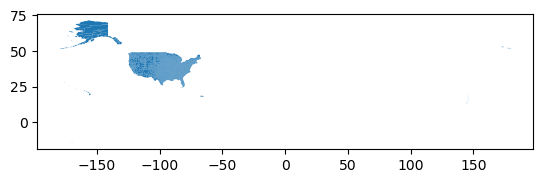

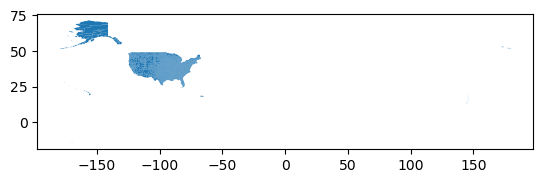

In [48]:
# d
counties.plot()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.B. Cleaning

Simplify column names as needed.

In [50]:
# Make all columns lower case
counties.columns = counties.columns.str.lower()
counties.columns

Index(['statefp', 'countyfp', 'countyns', 'geoid', 'geoidfq', 'name',
       'namelsad', 'lsad', 'classfp', 'mtfcc', 'csafp', 'cbsafp', 'metdivfp',
       'funcstat', 'aland', 'awater', 'intptlat', 'intptlon', 'geometry'],
      dtype='object')

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.C. Data selection

Select all the counties for the state of New York in a new variable `ny_counties` and plot them (you may need to look at the metadata).

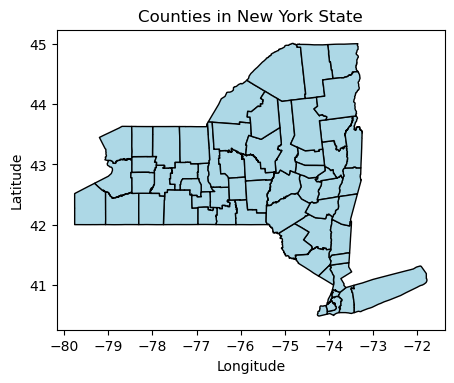

In [63]:

# Select counties only in NY state (check NY FIPS code)
ny_counties = counties.loc[counties['statefp'] == "36"]

# Plot counties
# Initialize an empty figure and axes
fig, ax = plt.subplots(figsize=(5, 4))

# Add New York counties to the figure's axes
ny_counties.plot(ax=ax,
                 color='lightblue',
                 edgecolor='black'
                )

# Update axes
ax.set_title('Counties in New York State')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

# Display figure
plt.show()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 7 Merging

The goal of this section is to create a single dataframe with the number of spills per county and the corresponding geometries for each county.

### 7.A. Explore data

In the next cells:

a. Print the names of counties in `ny_counties`, without repetition.


In [ ]:
# Print county names
print(ny_counties['name'].unique())

['Erie' 'Niagara' 'Jefferson' 'Steuben' 'Seneca' 'Rensselaer' 'Albany'
 'Saratoga' 'Schoharie' 'Schenectady' 'Ulster' 'Dutchess' 'Orange'
 'Columbia' 'Tompkins' 'Tioga' 'Broome' 'Cayuga' 'Genesee' 'Onondaga'
 'Oswego' 'Madison' 'Livingston' 'Monroe' 'Ontario' 'Orleans' 'Wayne'
 'Chautauqua' 'Sullivan' 'Chemung' 'Cattaraugus' 'Fulton' 'Montgomery'
 'Cortland' 'Warren' 'Washington' 'Otsego' 'Queens' 'Bronx' 'Nassau'
 'Westchester' 'Richmond' 'Kings' 'Suffolk' 'Rockland' 'New York' 'Putnam'
 'Clinton' 'St. Lawrence' 'Herkimer' 'Oneida' 'Yates' 'Greene' 'Schuyler'
 'Delaware' 'Hamilton' 'Lewis' 'Allegany' 'Chenango' 'Wyoming' 'Franklin'
 'Essex']


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Print the names of counties in `spills_per_county`, without repetition. Examine the differences in the outputs.

In [76]:
# Print names of counties in spills_per_county
print(spills_per_county['county'].unique())

['Albany' 'Allegany' 'Bronx' 'Broome' 'Cattaraugus' 'Cayuga' 'Chautauqua'
 'Chemung' 'Chenango' 'Clinton' 'Columbia' 'Cortland' 'Delaware'
 'Dutchess' 'Erie' 'Essex' 'Franklin' 'Fulton' 'Genesee' 'Greene'
 'Hamilton' 'Herkimer' 'Jefferson' 'Kings' 'Lewis' 'Livingston' 'Madison'
 'Monroe' 'Montgomery' 'Nassau' 'New Jersey - Region 2' 'New York'
 'Niagara' 'Oneida' 'Onondaga' 'Onondaga Indian Reservation' 'Ontario'
 'Orange' 'Orleans' 'Oswego' 'Otsego' 'Pennsylvania - Region 3' 'Putnam'
 'Queens' 'Rensselaer' 'Richmond' 'Rockland' 'Saratoga' 'Schenectady'
 'Schoharie' 'Schuyler' 'Seneca' 'St Lawrence' 'Steuben' 'Suffolk'
 'Sullivan' 'Tioga' 'Tompkins' 'Tuscarora Indian Reservation' 'Ulster'
 'Warren' 'Washington' 'Wayne' 'Westchester' 'Wyoming' 'Yates']


_The ny_counties dataframe contains 62 unique county names that are not listed in alphabetical order, whereas spills_per_county contains 66 unique county names listed alphabetically. Since New York State has 62 counties, the additional names in spills_per_county may represent inconsistencies in county naming, missing or incorrectly classified geographic information, or records that do not correspond to an official New York county._

<!-- END QUESTION -->



c. Which are the county names that are in `spills_per_county`, but not in `ny_counties`? Your answer should be a list of strings
HINT: You can use the `numpy` function [`setdiff1d()`](https://numpy.org/doc/stable/reference/generated/numpy.setdiff1d.html), pay attention to the example in the documentation. Store your answer in the `diff_names` variable. 


In [ ]:
# Find county names in spills_per_county that are not in ny_counties
diff_names_spills = np.setdiff1d( 
    spills_per_county['county'].unique(),
    ny_counties['name'].unique()
).tolist()

diff_names_spills


['New Jersey - Region 2',
 'Onondaga Indian Reservation',
 'Pennsylvania - Region 3',
 'St Lawrence',
 'Tuscarora Indian Reservation']

In [80]:
grader.check("7Ac")

7Ac results: All test cases passed!

d. Which are the county names that are in `ny_counties`, but not in `spills_per_county`? Your answer should be a list of a string/strings.


In [82]:
# Find county names in ny_counties that are not in spills_per_county
diff_names_ny = np.setdiff1d(
    ny_counties['name'].unique(),
    spills_per_county['county'].unique()
).tolist()
diff_names_ny


['St. Lawrence']

In [83]:
grader.check("7Ad")

7Ad results: All test cases passed!

e. What is the number of spills in 'Tuscarora Indian Reservation' and in 'Onondaga Indian Reservation'?


In [88]:
# e. Select spill records for the two reservations
spills_per_county.loc[
    spills_per_county['county'].isin([
        'Tuscarora Indian Reservation',
        'Onondaga Indian Reservation'
    ])
]

,county,n_spills
35,Onondaga Indian Reservation,1
58,Tuscarora Indian Reservation,2


### 7.B. Data updates

In the next cell, update 'St Lawrence' to 'St. Lawrence' in the `spills_per_county` data frame. Verify the update was successful with an assert test. 


In [89]:
# Update St Lawrence to St. Lawrence
spills_per_county['county'] = spills_per_county['county'].replace(
    'St Lawrence', 'St. Lawrence'
)

# Verify the update was successful
assert 'St. Lawrence' in spills_per_county['county'].values
assert 'St Lawrence' not in spills_per_county['county'].values

### 7.C. Merge

In the following cells:

a. Use this cell to make any other updates needed for making an inner join of the `spills_per_county` and `ny_counties`. HINT: [`pd.merge`](https://pandas.pydata.org/pandas-docs/version/2.3/reference/api/pandas.merge.html)


In [92]:
# Check for county names that do not match
np.setdiff1d(
    spills_per_county['county'].unique(),
    ny_counties['name'].unique()
)


array(['New Jersey - Region 2', 'Onondaga Indian Reservation',
       'Pennsylvania - Region 3', 'Tuscarora Indian Reservation'],
      dtype=object)

b. Store the inner join of the `spills_per_county` and `ny_counties` dataframes in a new variable named `ny_spills`.


In [93]:
# Merge spill counts with New York county geometries
ny_spills = pd.merge(
    spills_per_county,
    ny_counties,
    left_on='county',
    right_on='name',
    how='inner'
)

# Preview the merged dataframe
ny_spills.head()

,county,n_spills,statefp,countyfp,countyns,geoid,geoidfq,name,namelsad,lsad,...,mtfcc,csafp,cbsafp,metdivfp,funcstat,aland,awater,intptlat,intptlon,geometry
0,Albany,224,36,001,00974099,36001,0500000US36001,Albany,Albany County,06,...,G4020,104,10580,None,A,1354273428,26971923,+42.5882401,-073.9740095,"POLYGON ((-73.96379 42.44162, -73.96666 42.441..."
1,Allegany,32,36,003,00974100,36003,0500000US36003,Allegany,Allegany County,06,...,G4020,None,None,None,A,2666410162,12989705,+42.2478532,-078.0261531,"POLYGON ((-78.04342 42.51846, -78.04326 42.518..."
2,Bronx,152,36,005,00974101,36005,0500000US36005,Bronx,Bronx County,06,...,G4020,408,35620,35614,C,109301867,39287123,+40.8487111,-073.8529390,"POLYGON ((-73.93381 40.88221, -73.93365 40.882..."
3,Broome,80,36,007,00974102,36007,0500000US36007,Broome,Broome County,06,...,G4020,None,13780,None,A,1827626584,25078248,+42.1619773,-075.8302833,"POLYGON ((-75.74223 41.99805, -75.75080 41.997..."
4,Cattaraugus,45,36,009,00974103,36009,0500000US36009,Cattaraugus,Cattaraugus County,06,...,G4020,160,36460,None,A,3388177044,36783591,+42.2390986,-078.6623320,"POLYGON ((-78.69725 41.99867, -78.69881 41.998..."


<!-- BEGIN QUESTION -->

c. An inner join only keeps the rows whose `county` appears in both dataframes, and it does not warn you about the rows it drops. Which records from `spills_per_county` were dropped by the inner join, and how many spills did each one have? Add the cells you need to find the dropped records.

In [94]:
# Find records in spills_per_county that were dropped during the inner join
dropped_records = spills_per_county.loc[
    ~spills_per_county['county'].isin(ny_spills['county'])
]

# Display dropped records and their spill counts
dropped_records

,county,n_spills
30,New Jersey - Region 2,7
35,Onondaga Indian Reservation,1
41,Pennsylvania - Region 3,1
58,Tuscarora Indian Reservation,2


In [95]:
# Count the number of dropped records
len(dropped_records)

4

The inner join dropped four records from spills_per_county, representing a total of 11 spills. These included New Jersey - Region 2 (7 spills), Onondaga Indian Reservation (1 spill), Pennsylvania - Region 3 (1 spill), and Tuscarora Indian Reservation (2 spills). These records were excluded because their geographic names did not match any county names in the ny_counties GeoDataFrame.

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Does dropping these records affect the map or the information we will report? Write your answer in the following markdown cell.

_Yes, dropping these 4 records affects the information we report because 11 spills are excluded from the merged dataset. The records from New Jersey and Pennsylvania fall outside New York State, so excluding them makes sense for our county-level map. However, the Onondaga and Tuscarora Indian Reservations are located within New York State, and excluding their records could lead to an underrepresentation of spills in those areas. Their exclusion should be acknowledged when interpreting the map and reporting the total number of spills._

<!-- END QUESTION -->


From our previous exploration we know that Tuscarora Indian Reservation and Onondaga Indian Reservation will not be in the join. Tuscarora Indian Reservation is located within Niagara county and Onondaga Indian Reservation is located within Onondaga county. 

e. Since the reservations do not appear in the `ny_counties` dataframe, add the Tuscarora Indian Reservation spills to Niagara county and the Onondaga Indian Reservation spills to Onondaga county in `ny_spills`. We will add a note about this in our final map, and we will reflect on this choice in exercise 8.b. Add the cells you need to make this update **and** verify that the dataframe was updated.

In [98]:
# Add reservation spills to corresponding counties
ny_spills.loc[ny_spills['county'] == 'Niagara', 'n_spills'] += 2
ny_spills.loc[ny_spills['county'] == 'Onondaga', 'n_spills'] += 1

# Verify the updated spill counts
ny_spills.loc[ny_spills['county'].isin(['Niagara', 'Onondaga']),
              ['county', 'n_spills']]


,county,n_spills
31,Niagara,103
33,Onondaga,217


## 8. Map
a. Create a choropleth map of the number of petroleum spills per county in the state of New York in 2023. 
Your map should be polished and have (at least) the following updates:
- a legend indicating the number of spills
- an updated color map
- a title 
- no axis
- an annotation with the data source (New York State Department of Environmental Conservation) and date of access



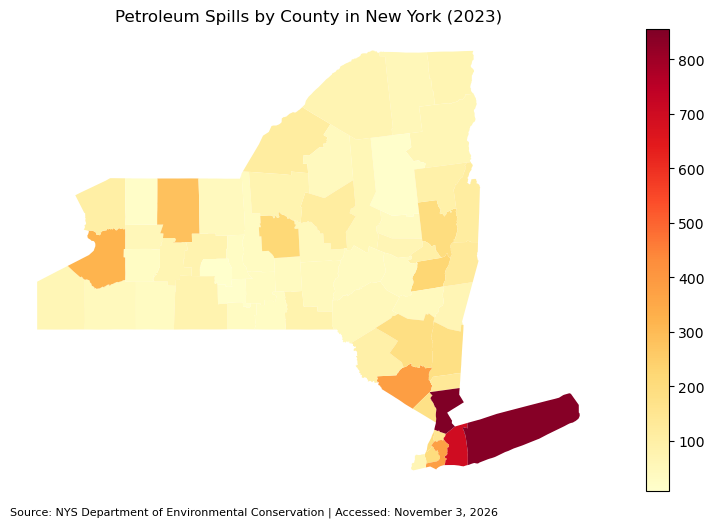

In [102]:
# Convert to GeoDataFrame
ny_spills = gpd.GeoDataFrame(ny_spills, geometry='geometry', crs=ny_counties.crs)

# Create choropleth map
ax = ny_spills.plot(column='n_spills',
                   cmap='YlOrRd',
                   legend=True,
                   figsize=(10, 6))

# Update map
ax.set_title('Petroleum Spills by County in New York (2023)')
ax.set_axis_off()

# Add data source
ax.text(0, -0.05,
        'Source: NYS Department of Environmental Conservation | Accessed: November 3, 2026',
        transform=ax.transAxes,
        fontsize=8)

plt.show()



b. Write a description of how the map was created, including key takeaways. If you need to do additional data analysis to include relevant information from the data, you may include additional cells here.

In your description, also reflect on how we handled the spills reported in the Tuscarora and Onondaga Indian Reservations (exercise 7.C.e) in terms of data governance and the CARE Principles for Indigenous Data Governance from Task 1.

### Map Description

This choropleth map illustrates the number of reported petroleum spills across New York State counties in 2023, using data from the [New York State Department of Environmental Conservation](https://data.ny.gov/Energy-Environment/Spill-Incidents/u44d-k5fk/about_data) and county boundaries from the [U.S. Census Bureau](https://www2.census.gov/geo/pdfs/maps-data/data/tiger/tgrshp2026/TGRSHP2026_TechDoc.pdf).

I selected a **choropleth map** because it allows us to compare numerical values across geographic areas ([GeoPandas](https://geopandas.org/en/stable/docs/user_guide/mapping.html)). After merging the datasets, I converted `ny_spills` into a GeoDataFrame to enable geographic plotting using county geometries. I chose the **Yellow–Orange–Red (`YlOrRd`) color palette** because it communicates increasing numerical values, with lighter colors representing fewer spills and darker colors representing more spills.

### Key Takeaways

The map shows that reported petroleum spills are unevenly distributed across New York State. Counties around New York City and Long Island have the highest spill counts, while northern and central counties generally have fewer reported spills. These patterns may be influenced by population density, infrastructure, and industrial activity. However, the map does not account for population size, county area, or spill severity, so it cannot establish the causes or relative risks of petroleum spills.

### Reflection on Indigenous Data Governance

During data preparation, I added two spills from the Tuscarora Indian Reservation to Niagara County and one spill from the Onondaga Indian Reservation to Onondaga County because the reservations were not represented separately in the county boundary dataset.

While this allowed the spills to be included in the map, it also removed the distinction between incidents reported on Indigenous lands and those reported elsewhere in the counties. This raises concerns under the [The CARE Principles for Indigenous Data Governance](https://static1.squarespace.com/static/5d3799de845604000199cd24/t/6397b1aff7a6fb54defdf687/1670885815820/dsj-1158_carroll.pdf), particularly *Authority to Control* and *Ethics*, which emphasize Indigenous communities' rights to govern how data concerning their lands and communities are used and represented. A more responsible approach would involve consulting with the affected Indigenous Nations and exploring ways to preserve their geographic identities while respecting Indigenous data sovereignty.

## Complete workflow

Collect all the relevant code into the first blank cell of the notebook titled "COMPLETE WORKFLOW". This single cell will have the end-to-end workflow: from importing libraries and loading the data, to producing the choropleth map of the number of petroleum spills per county in the state of New York in 2023. The only output of this cell should be the choropleth map  you produced in the previous exercise. Further guidance on what to include in this final workflow is in the assignment rubric.